# 04 · Feature-selection experiments (RQ2)

The core optimization study. Four methods search the 2^45 feature subsets for the lowest fitness

$$f(\mathbf{x}) = 0.99\,\bigl(1 - \text{PR-AUC}_{\text{val}}(\mathbf{x})\bigr) + 0.01\,\frac{|\mathbf{x}|}{45}$$

GA, Binary PSO, Binary GWO and random search, each with 600 evaluations, population 20, the same starting population per seed, and seeds 0 to 9.
The runs come from `python run_experiments.py` (one CSV and one JSON per algorithm and seed in `results/feature_selection/`).
This notebook checks the files and compares the methods:

1. run files (T5.1)
2. summary table and the H2a check (T5.2)
3. convergence (T5.3)
4. population diversity (T5.4)
5. subset stability (T5.5)
6. statistical tests (T5.6)
7. ablation: Binary PSO with the plan's falling inertia weight
8. the α trade-off sweep (T5.7)
9. verdicts on H2a, H2b and H2c (T5.8)

**Everything here is measured on the validation set.** The test set is used in notebook 05.

In [1]:
import json
import sys
from itertools import combinations
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

from src import config, data
from src.features import D, FEATURES, pretty
from src.fitness import FitnessFunction, bits_to_mask
from src.plotting import (AQUA, BLUE, GRAY, INK_SECONDARY, METHOD_LABEL, METHODS, MUTED, ORANGE,
                          method_kwargs, plt, save, set_style)

set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)
TABLES = config.RESULTS / "tables"
SEEDS = list(config.RUN_SEEDS)
LABEL = dict(METHOD_LABEL, bpso_w_dec="Binary PSO, w 0.9→0.4")


def load_runs(folder, algs, seeds, alpha=config.ALPHA):
    """Summaries (one row per run) and per-call logs of a set of runs."""
    rows, logs = [], {}
    for alg in algs:
        for seed in seeds:
            name = f"{alg}_seed{seed}" if alpha == config.ALPHA else f"{alg}_alpha{alpha:.2f}_seed{seed}"
            summary = json.loads((folder / f"{name}.json").read_text())
            logs[(alg, seed)] = pd.read_csv(folder / f"{name}.csv", dtype={"mask": str})
            rows.append(summary)
    return pd.DataFrame(rows), logs


runs, logs = load_runs(config.FS_DIR, METHODS, SEEDS)
print(f"{len(runs)} runs loaded")

40 runs loaded


## 1. Run files (T5.1)

In [2]:
checks = []
for (alg, seed), log in logs.items():
    summary = runs[(runs["algorithm"] == alg) & (runs["seed"] == seed)].iloc[0]
    checks.append({
        "algorithm": alg, "seed": seed,
        "600 calls": len(log) == config.BUDGET,
        "no NaN": not log.isna().any().any(),
        "best-so-far never rises": bool(np.all(np.diff(log["best_so_far"]) <= 1e-15)),
        "summary matches log": np.isclose(log["fitness"].min(), summary["best_fitness"]),
        "no empty subset": bool((log["n_features"] >= 1).all()),
    })
checks = pd.DataFrame(checks)
print("all checks pass:", bool(checks.drop(columns=["algorithm", "seed"]).all().all()))

# fairness: for every seed, the first 20 subsets evaluated are the same for all four methods
same_start = all(
    len({tuple(logs[(alg, seed)]["mask"].iloc[:config.POP_SIZE]) for alg in METHODS}) == 1 for seed in SEEDS)
print("every seed starts all four methods from the same 20 subsets:", same_start)
assert checks.drop(columns=["algorithm", "seed"]).all().all() and same_start

all checks pass: True
every seed starts all four methods from the same 20 subsets: True


## 2. Summary table and the H2a check (T5.2)

The reference is LightGBM on **all 45 features with the same fixed settings** the fitness function uses (decision D18).
H2a asks for a subset of at most D/3 = 15 features whose validation PR-AUC is within 0.01 of that reference.

In [3]:
df = data.load_main()
X_train, y_train = data.get_xy(df, "train")
X_val, y_val = data.get_xy(df, "val")
reference = FitnessFunction(X_train, y_train, X_val, y_val)
ref_fitness = reference(np.ones(D, dtype=np.uint8))
ref_pr_auc = reference.log[-1]["pr_auc"]
print(f"all 45 features, fixed settings: fitness {ref_fitness:.5f}, validation PR-AUC {ref_pr_auc:.4f}")

runs["minutes"] = runs["wall_seconds"] / 60
runs["H2a size (<= 15)"] = runs["n_features"] <= D // 3
runs["H2a accuracy (>= ref - 0.01)"] = runs["best_pr_auc"] >= ref_pr_auc - 0.01
agg = runs.groupby("algorithm").agg(
    fitness_mean=("best_fitness", "mean"), fitness_sd=("best_fitness", "std"),
    pr_auc_mean=("best_pr_auc", "mean"), pr_auc_sd=("best_pr_auc", "std"),
    features_mean=("n_features", "mean"), features_sd=("n_features", "std"),
    features_min=("n_features", "min"), features_max=("n_features", "max"),
    minutes_mean=("minutes", "mean"), distinct_subsets=("n_trainings", "mean"),
    call_of_best=("first_hit_call", "mean"),
    runs_meeting_H2a=("H2a size (<= 15)", lambda s: int((s & runs.loc[s.index, "H2a accuracy (>= ref - 0.01)"]).sum())),
).loc[METHODS]
agg.index = [METHOD_LABEL[a] for a in agg.index]
agg.loc["All 45 features (fixed settings)"] = pd.Series({"fitness_mean": ref_fitness, "pr_auc_mean": ref_pr_auc, "features_mean": D})
agg.round(4).to_csv(TABLES / "rq2_summary.csv")
agg.round(4)

all 45 features, fixed settings: fitness 0.50567, validation PR-AUC 0.4993


,fitness_mean,fitness_sd,pr_auc_mean,pr_auc_sd,features_mean,features_sd,features_min,features_max,minutes_mean,distinct_subsets,call_of_best,runs_meeting_H2a
GA,0.3889,0.0194,0.6122,0.0194,22.1,1.9692,20.0,25.0,3.1421,455.4,365.6,0.0
Binary PSO,0.3796,0.0114,0.6214,0.0114,21.6,2.0656,17.0,24.0,4.0534,594.8,507.5,0.0
Binary GWO,0.3733,0.0070,0.6270,0.0069,17.9,2.0790,16.0,22.0,2.4864,381.3,391.2,0.0
Random search,0.4261,0.0074,0.5749,0.0075,23.7,2.6687,19.0,27.0,3.9704,600.0,236.7,0.0
All 45 features (fixed settings),0.5057,NaN,0.4993,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Two things stand out before any test:

* **Every method beats the all-feature model on validation by a wide margin** (PR-AUC 0.57 to 0.63 against 0.50), so on the accuracy side H2a is met many times over. Feature selection is raising accuracy here, not merely holding it.
* **No run reaches 15 features or fewer.** With α = 0.99 one feature is worth only 0.01/45 ≈ 0.0002 of fitness, which a PR-AUC gain of 0.0002 cancels, so the optimizers keep 16 to 25 features. H2a's size condition fails at the planned α; section 8 shows what happens when size counts for more.

## 3. Convergence (T5.3)

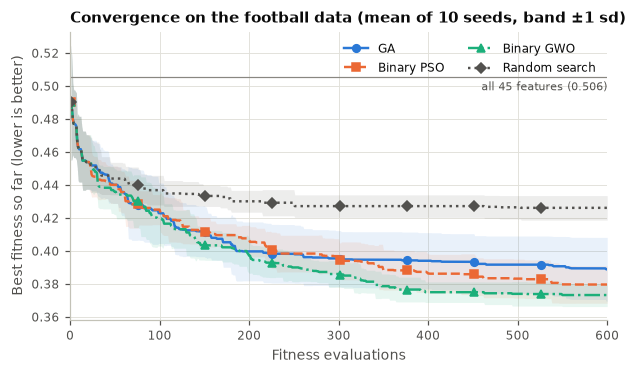

In [4]:
curves = {alg: np.array([logs[(alg, s)]["best_so_far"].to_numpy() for s in SEEDS]) for alg in METHODS}
calls = np.arange(1, config.BUDGET + 1)

fig, ax = plt.subplots(figsize=(6.3, 3.4))
for alg in METHODS:
    mean, sd = curves[alg].mean(axis=0), curves[alg].std(axis=0, ddof=1)
    kw = method_kwargs(alg)
    ax.plot(calls, mean, markevery=75, **kw)
    ax.fill_between(calls, mean - sd, mean + sd, color=kw["color"], alpha=0.10, linewidth=0)
ax.axhline(ref_fitness, color=MUTED, linewidth=0.8)
ax.annotate(f"all 45 features ({ref_fitness:.3f})", (config.BUDGET, ref_fitness), xytext=(0, -3), textcoords="offset points",
            ha="right", va="top", fontsize=7.5, color=INK_SECONDARY)
ax.set(xlabel="Fitness evaluations", ylabel="Best fitness so far (lower is better)",
       title="Convergence on the football data (mean of 10 seeds, band ±1 sd)", xlim=(0, config.BUDGET))
ax.legend(loc="upper right", ncols=2)
save(fig, "fig04a_convergence")
plt.show()

In [5]:
milestones = [20, 100, 200, 300, 400, 600]
conv = pd.DataFrame({METHOD_LABEL[a]: [curves[a][:, m - 1].mean() for m in milestones] for a in METHODS},
                    index=pd.Index(milestones, name="after this many calls")).T
random_final = curves["random"][:, -1].mean()
conv["calls until mean curve beats random search's final value"] = [
    int(np.argmax(curves[a].mean(axis=0) < random_final)) + 1 if (curves[a].mean(axis=0) < random_final).any() else np.nan
    for a in METHODS]
conv.round(4)

after this many calls,20,100,200,300,400,600,calls until mean curve beats random search's final value
GA,0.4539,0.4229,0.3997,0.3953,0.3940,0.3889,83.0
Binary PSO,0.4539,0.4251,0.4067,0.3968,0.3863,0.3796,80.0
Binary GWO,0.4539,0.4197,0.3971,0.3860,0.3750,0.3733,85.0
Random search,0.4539,0.4369,0.4301,0.4272,0.4272,0.4261,NaN


## 4. Population diversity (T5.4)

Mean pairwise Hamming distance of the population after each iteration, plotted against the evaluations used so far (the GA spends 18 calls per generation, the swarms 20).
A population of random 0/1 vectors has an expected distance of D/2 = 22.5. Random search has no population, so it has no curve.

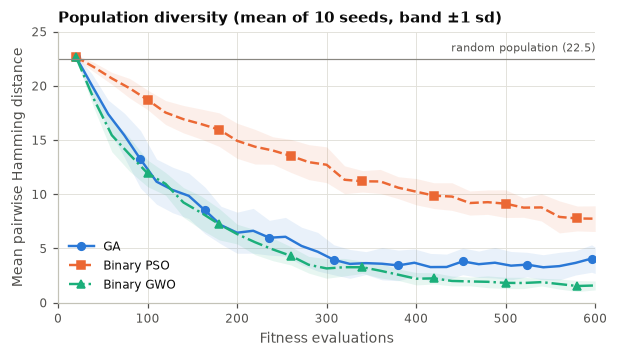

,start,after ~100 calls,after ~300 calls,end
GA,22.66,11.16,4.70,3.91
Binary PSO,22.66,17.54,11.34,7.75
Binary GWO,22.66,10.96,3.27,1.59


In [6]:
def evaluations_at_iterations(alg, n):
    step = config.POP_SIZE - 2 if alg in ("ga",) else config.POP_SIZE
    return np.minimum(config.POP_SIZE + step * np.arange(n), config.BUDGET)


fig, ax = plt.subplots(figsize=(6.3, 3.2))
diversity_table = {}
for alg in ["ga", "bpso", "bgwo"]:
    div = np.array([runs[(runs["algorithm"] == alg) & (runs["seed"] == s)]["diversity"].iloc[0] for s in SEEDS])
    x = evaluations_at_iterations(alg, div.shape[1])
    ax.plot(x, div.mean(axis=0), markevery=4, **method_kwargs(alg))
    ax.fill_between(x, div.mean(axis=0) - div.std(axis=0, ddof=1), div.mean(axis=0) + div.std(axis=0, ddof=1),
                    color=method_kwargs(alg)["color"], alpha=0.10, linewidth=0)
    diversity_table[METHOD_LABEL[alg]] = {"start": div[:, 0].mean(), "after ~100 calls": div[:, 5].mean(),
                                          "after ~300 calls": div[:, 15].mean(), "end": div[:, -1].mean()}
ax.axhline(D / 2, color=MUTED, linewidth=0.8)
ax.annotate("random population (22.5)", (config.BUDGET, D / 2), xytext=(0, 3), textcoords="offset points",
            ha="right", va="bottom", fontsize=7.5, color=INK_SECONDARY)
ax.set(xlabel="Fitness evaluations", ylabel="Mean pairwise Hamming distance",
       title="Population diversity (mean of 10 seeds, band ±1 sd)", xlim=(0, config.BUDGET), ylim=(0, 25))
ax.legend(loc="lower left")
save(fig, "fig04b_diversity")
plt.show()
pd.DataFrame(diversity_table).T.round(2)

## 5. Subset stability (T5.5)

Jaccard similarity of two subsets = shared features ÷ features in either. For each method, the mean over all 45 pairs of its 10 final subsets.
Two random subsets of about 20 features out of 45 would have a Jaccard similarity of roughly 0.3.

In [7]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)


stability = {}
for alg in METHODS:
    subsets = runs.loc[runs["algorithm"] == alg, "best_features"].tolist()
    pair_values = [jaccard(a, b) for a, b in combinations(subsets, 2)]
    freq = pd.Series([f for s in subsets for f in s]).value_counts()
    stability[METHOD_LABEL[alg]] = {
        "mean Jaccard (45 pairs)": np.mean(pair_values), "sd": np.std(pair_values, ddof=1),
        "min": np.min(pair_values), "max": np.max(pair_values),
        "features in all 10 subsets": int((freq == 10).sum()),
        "features in at least 8": int((freq >= 8).sum()),
    }
stability = pd.DataFrame(stability).T
stability.round(3).to_csv(TABLES / "rq2_stability.csv")
stability.round(3)

,mean Jaccard (45 pairs),sd,min,max,features in all 10 subsets,features in at least 8
GA,0.410,0.078,0.265,0.679,2.0,8.0
Binary PSO,0.436,0.090,0.242,0.692,4.0,8.0
Binary GWO,0.387,0.092,0.172,0.600,1.0,7.0
Random search,0.385,0.077,0.212,0.545,0.0,6.0


In [8]:
def core(alg, k=8):
    freq = pd.Series([f for s in runs.loc[runs["algorithm"] == alg, "best_features"] for f in s]).value_counts()
    return [pretty(f) for f in freq[freq >= k].index]


for alg in ["ga", "bpso", "bgwo"]:
    print(f"{METHOD_LABEL[alg]:11s} features in at least 8 of 10 runs: {', '.join(core(alg))}")

GA          features in at least 8 of 10 runs: Age, Height, Heading accuracy, Volleys, Balance, Position group, Short passing, Acceleration
Binary PSO  features in at least 8 of 10 runs: Age, Height, Interceptions, Penalties, Finishing, Volleys, Balance, Vision
Binary GWO  features in at least 8 of 10 runs: Age, Height, Volleys, Sliding tackle, Pace (face), Acceleration, Balance


## 6. Statistical tests (T5.6)

Following Derrac et al. (2011): a Friedman test across the four methods first, then Wilcoxon signed-rank tests on the six pairs,
paired by seed (both runs of a pair started from the same population), with Holm's correction for six comparisons.
The response is the best fitness of each run. With 10 pairs the smallest possible two-sided p-value is 2/1024 ≈ 0.002.

In [9]:
fit = runs.pivot(index="seed", columns="algorithm", values="best_fitness")[METHODS]
friedman = friedmanchisquare(*[fit[a] for a in METHODS])
mean_ranks = fit.rank(axis=1).mean().rename(index=METHOD_LABEL)
print(f"Friedman test: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2e}")
print("mean rank (1 = best):", mean_ranks.round(2).to_dict())

pairs = [("ga", "random"), ("bpso", "random"), ("bgwo", "random"), ("ga", "bpso"), ("ga", "bgwo"), ("bpso", "bgwo")]
rows = []
for a, b in pairs:
    test = wilcoxon(fit[a], fit[b])
    rows.append({"comparison": f"{METHOD_LABEL[a]} vs {METHOD_LABEL[b]}",
                 "mean difference (a - b)": (fit[a] - fit[b]).mean(),
                 "seeds where a is better": int((fit[a] < fit[b]).sum()),
                 "W": test.statistic, "p": test.pvalue})
tests = pd.DataFrame(rows)
tests["p (Holm)"] = multipletests(tests["p"], method="holm")[1]
tests["significant at 0.05"] = tests["p (Holm)"] < 0.05
tests.round(4).to_csv(TABLES / "rq2_wilcoxon_holm.csv", index=False)
tests.round(4)

Friedman test: chi2 = 19.92, p = 1.76e-04
mean rank (1 = best): {'GA': 2.4, 'Binary PSO': 2.0, 'Binary GWO': 1.6, 'Random search': 4.0}


,comparison,mean difference (a - b),seeds where a is better,W,p,p (Holm),significant at 0.05
0,GA vs Random search,-0.0373,10,0.0,0.0020,0.0117,True
1,Binary PSO vs Random search,-0.0465,10,0.0,0.0020,0.0117,True
2,Binary GWO vs Random search,-0.0529,10,0.0,0.0020,0.0117,True
3,GA vs Binary PSO,0.0092,3,15.0,0.2324,0.4648,False
4,GA vs Binary GWO,0.0156,3,12.0,0.1309,0.3926,False
5,Binary PSO vs Binary GWO,0.0064,3,16.0,0.2754,0.4648,False


Secondary comparison, not part of the Holm family: the same tests on the **number of selected features**.

In [10]:
size = runs.pivot(index="seed", columns="algorithm", values="n_features")[METHODS]
size_rows = []
for a, b in pairs:
    test = wilcoxon(size[a], size[b]) if (size[a] != size[b]).any() else None
    size_rows.append({"comparison": f"{METHOD_LABEL[a]} vs {METHOD_LABEL[b]}", "mean difference in features (a - b)": (size[a] - size[b]).mean(),
                      "p": test.pvalue if test else np.nan})
size_tests = pd.DataFrame(size_rows)
size_tests["p (Holm)"] = multipletests(size_tests["p"].fillna(1), method="holm")[1]
size_tests.round(4)

,comparison,mean difference in features (a - b),p,p (Holm)
0,GA vs Random search,-1.6,0.1113,0.3340
1,Binary PSO vs Random search,-2.1,0.2656,0.5312
2,Binary GWO vs Random search,-5.8,0.0039,0.0234
3,GA vs Binary PSO,0.5,0.9316,0.9316
4,GA vs Binary GWO,4.2,0.0039,0.0234
5,Binary PSO vs Binary GWO,3.7,0.0098,0.0391


## 7. Ablation: Binary PSO with the plan's falling inertia weight

Notebook 03 replaced the plan's inertia schedule (0.9 → 0.4) with w = 1 after the toy test (decision D21).
The same 10 seeds were run on the football data with the original schedule, to see what the change is worth here.

In [11]:
ablation, ablation_logs = load_runs(config.RESULTS / "ablation_bpso_inertia", ["bpso_w_dec"], SEEDS)
paired = pd.DataFrame({"Binary PSO, w = 1": fit["bpso"].to_numpy(),
                       "Binary PSO, w 0.9→0.4": ablation.sort_values("seed")["best_fitness"].to_numpy()}, index=SEEDS)
test = wilcoxon(paired.iloc[:, 0], paired.iloc[:, 1])
abl = pd.DataFrame({
    "fitness mean": paired.mean(), "fitness sd": paired.std(),
    "PR-AUC mean": [runs.loc[runs["algorithm"] == "bpso", "best_pr_auc"].mean(), ablation["best_pr_auc"].mean()],
    "features mean": [runs.loc[runs["algorithm"] == "bpso", "n_features"].mean(), ablation["n_features"].mean()],
    "final diversity": [np.mean([d[-1] for d in runs.loc[runs["algorithm"] == "bpso", "diversity"]]),
                        np.mean([d[-1] for d in ablation["diversity"]])],
})
print(f"w = 1 better on {(paired.iloc[:, 0] < paired.iloc[:, 1]).sum()} of 10 seeds; Wilcoxon p = {test.pvalue:.4f}")
print(f"falling-weight PSO vs random search: better on {(paired.iloc[:, 1].to_numpy() < fit['random'].to_numpy()).sum()} of 10 seeds")
abl.round(4)

w = 1 better on 10 of 10 seeds; Wilcoxon p = 0.0020
falling-weight PSO vs random search: better on 10 of 10 seeds


,fitness mean,fitness sd,PR-AUC mean,features mean,final diversity
"Binary PSO, w = 1",0.3796,0.0114,0.6214,21.6,7.7474
"Binary PSO, w 0.9→0.4",0.4076,0.0069,0.5931,21.6,20.6084


## 8. The α trade-off sweep (T5.7)

α sets the price of a feature. Binary GWO, the method with the lowest mean fitness and the smallest spread (sections 2 and 6), was rerun with α = 0.95, 0.90 and 0.80, five seeds each (seeds 0 to 4).
The PR-AUC cache from the main runs was reused (`--reuse-cache`): the PR-AUC of a subset does not depend on α, so this changes the cost, not the result.

Every subset evaluated in any run is also a point (number of features, validation PR-AUC). The best PR-AUC seen at each subset size traces an **empirical Pareto front**: you cannot get more accuracy without more features.

In [12]:
sweep_alphas = [config.ALPHA] + list(config.SWEEP_ALPHAS)
sweep = [runs[runs["algorithm"] == "bgwo"].assign(alpha=config.ALPHA)]
sweep_logs = {}
for alpha in config.SWEEP_ALPHAS:
    s, l = load_runs(config.SWEEP_DIR, ["bgwo"], config.SWEEP_SEEDS, alpha=alpha)
    sweep.append(s.assign(alpha=alpha))
    sweep_logs.update({(alpha, k[1]): v for k, v in l.items()})
sweep = pd.concat(sweep, ignore_index=True)

sweep_table = sweep.groupby("alpha").agg(runs=("seed", "size"), pr_auc_mean=("best_pr_auc", "mean"), pr_auc_sd=("best_pr_auc", "std"),
                                         features_mean=("n_features", "mean"), features_min=("n_features", "min"),
                                         features_max=("n_features", "max")).sort_index(ascending=False)
sweep_table["runs meeting H2a"] = [int(((g["n_features"] <= 15) & (g["best_pr_auc"] >= ref_pr_auc - 0.01)).sum())
                                   for _, g in sweep.groupby("alpha")][::-1]
sweep_table.round(4).to_csv(TABLES / "rq2_alpha_sweep.csv")
sweep_table.round(4)

,runs,pr_auc_mean,pr_auc_sd,features_mean,features_min,features_max,runs meeting H2a
alpha,,,,,,,
0.99,10,0.6270,0.0069,17.9,16,22,0
0.95,5,0.6280,0.0134,14.6,14,15,5
0.90,5,0.6333,0.0085,15.0,14,17,4
0.80,5,0.6313,0.0079,9.6,8,12,5


In [13]:
all_logs = list(logs.values()) + list(ablation_logs.values()) + list(sweep_logs.values())
points = pd.concat([l[["mask", "n_features", "pr_auc"]] for l in all_logs]).drop_duplicates("mask")
best_by_size = points.groupby("n_features")["pr_auc"].max()
front = best_by_size[best_by_size > best_by_size.cummax().shift(fill_value=-1)]   # strictly better than every smaller size
print(f"{len(points):,} distinct subsets evaluated across all runs")
front_table = pd.DataFrame({"best validation PR-AUC": front,
                            "gain over one fewer front step": front.diff()}).rename_axis("features")
front_table.round(4).T

30,132 distinct subsets evaluated across all runs


features,6,7,8,9,12,15
best validation PR-AUC,0.5656,0.6019,0.6200,0.6374,0.6398,0.6471
gain over one fewer front step,NaN,0.0364,0.0181,0.0174,0.0024,0.0073


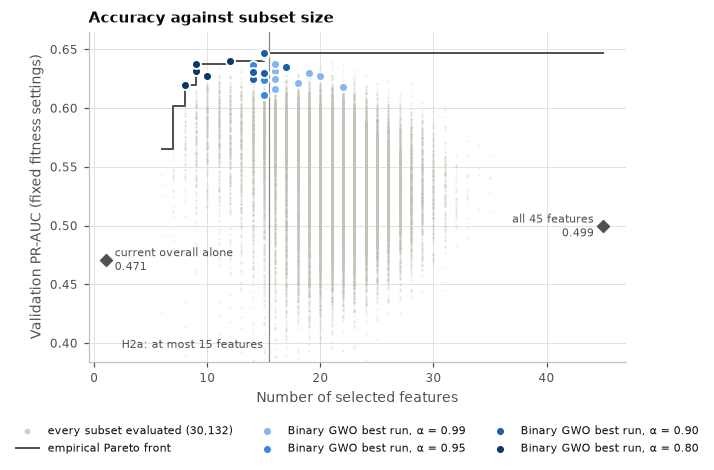

In [14]:
alpha_colors = {0.99: "#86b6ef", 0.95: "#3987e5", 0.90: "#1c5cab", 0.80: "#0d366b"}
overall_alone = FitnessFunction(X_train, y_train, X_val, y_val)
overall_alone(np.eye(D, dtype=np.uint8)[FEATURES.index("overall")])
overall_pr_auc = overall_alone.log[-1]["pr_auc"]

fig, ax = plt.subplots(figsize=(6.3, 3.9))
ax.scatter(points["n_features"], points["pr_auc"], s=2, color="#c3c2b7", alpha=0.25, linewidths=0, zorder=1,
           label="every subset evaluated (30,132)")
front_x = np.append(front.index.to_numpy(), D)
front_y = np.append(front.to_numpy(), front.iloc[-1])
ax.step(front_x, front_y, where="post", color=GRAY, linewidth=1.3, zorder=2, label="empirical Pareto front")
for alpha in sweep_alphas:
    g = sweep[sweep["alpha"] == alpha]
    ax.scatter(g["n_features"], g["best_pr_auc"], s=34, color=alpha_colors[alpha], edgecolor="white", linewidth=1.2,
               zorder=3, label=f"Binary GWO best run, α = {alpha:.2f}")
for x, y, text, ha in ((D, ref_pr_auc, f"all 45 features\n{ref_pr_auc:.3f}", "right"),
                       (1, overall_pr_auc, f"current overall alone\n{overall_pr_auc:.3f}", "left")):
    ax.scatter([x], [y], marker="D", s=30, color=INK_SECONDARY, zorder=4)
    ax.annotate(text, (x, y), xytext=(-6 if ha == "right" else 6, 0), textcoords="offset points", ha=ha, va="center",
                fontsize=7.5, color=INK_SECONDARY)
ax.axvline(15.5, color=MUTED, linewidth=0.8)
y_low = min(points["pr_auc"].quantile(0.002), overall_pr_auc) - 0.02
ax.annotate("H2a: at most 15 features", (15.5, y_low + 0.012), xytext=(-4, 0), textcoords="offset points", ha="right",
            fontsize=7.5, color=INK_SECONDARY)
ax.set(xlabel="Number of selected features", ylabel="Validation PR-AUC (fixed fitness settings)",
       title="Accuracy against subset size", xlim=(-0.5, 47), ylim=(y_low, 0.665))
legend = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=3, fontsize=7.5)
legend.legend_handles[0].set_sizes([14])
legend.legend_handles[0].set_alpha(0.8)
save(fig, "fig04c_tradeoff_front")
plt.show()

## 9. Verdicts (T5.8)

**H2a: partly supported.** *GA, Binary PSO and Binary GWO each find a subset of at most 15 features whose validation PR-AUC is within 0.01 of the all-feature model.*
The accuracy half holds by a wide margin: every one of the 30 metaheuristic runs beats the all-feature model (0.499) by 0.11 to 0.15 PR-AUC.
The size half fails at the planned α = 0.99: the smallest subsets have 16 (Binary GWO), 17 (Binary PSO) and 20 (GA) features, because a feature costs only 0.0002 of fitness.
When a feature costs more, small subsets appear without losing accuracy: Binary GWO at α = 0.95, 0.90 and 0.80 meets H2a in 14 of 15 runs, and at α = 0.80 it keeps 8 to 12 features with validation PR-AUC 0.620 to 0.640.
Only Binary GWO was swept, so for GA and Binary PSO the size condition is not shown.

**H2b: supported.** *All three beat random search under the same budget.*
Each metaheuristic has a lower final fitness than random search on all 10 seeds (Wilcoxon p = 0.002, Holm-adjusted 0.012 for each; Friedman p = 1.8 × 10⁻⁴).
The mean gain in fitness is 0.037 (GA), 0.047 (Binary PSO) and 0.053 (Binary GWO), which is almost all PR-AUC. All three pass random search's final value after 80 to 85 evaluations, so most of the budget goes to improvements random sampling never finds.

**H2c: partly supported.** *The three optimizers differ in convergence speed and subset stability, even when final PR-AUC is similar.*

* Final fitness: no pairwise difference survives the Holm correction (p ≥ 0.39). Binary GWO has the best mean rank (1.6, against 2.0 for Binary PSO and 2.4 for GA) and the smallest spread across seeds (sd 0.007, against 0.011 and 0.019).
* Convergence: the three curves overlap for the first 100 evaluations. GA then flattens (its mean best fitness improves by only 0.006 after call 300), while Binary GWO and Binary PSO keep improving until about call 400 and 550.
* Exploration: the populations behave very differently. Binary GWO's pack converges onto near-identical solutions (mean Hamming distance 1.6 at the end), GA keeps about 4 bits of variation and Binary PSO with w = 1 still differs in 7.7 bits. Binary PSO therefore spends almost every call on a new subset (595 of 600 distinct), while Binary GWO revisits subsets (381 distinct).
* Subset size: Binary GWO selects significantly fewer features (17.9 on average) than Binary PSO (21.6) and GA (22.1); Holm-adjusted p = 0.039 and 0.023.
* **Stability does not differ: it is low for every method.** Mean Jaccard similarity between runs is 0.39 (Binary GWO), 0.41 (GA) and 0.44 (Binary PSO), against 0.385 for random search's best subsets. Only age, height, volleys and balance are in at least 8 of 10 subsets for all three methods. Many quite different subsets reach almost the same validation PR-AUC, so a single run's subset is not a reliable scouting checklist. This matches the stability warning in Xue et al. (2016, §VI.C).

**Ablation.** Binary PSO with the plan's falling inertia weight loses to w = 1 on all 10 seeds (fitness 0.408 against 0.380, p = 0.002) and its swarm never contracts (final Hamming distance 20.6, close to a random population's 22.5). It still beats random search on every seed, so the binary update itself works; the schedule only disables convergence. The toy-problem decision (D21) holds on the real problem.

**Something the plan did not expect.** Feature selection here raises validation accuracy instead of trading it away: the best subsets score 0.62 to 0.65 against 0.50 for all 45 features under the same settings, and even above the tuned all-feature model (0.593). Part of this is real (some attributes change meaning between game versions), and part is selection on the validation set itself. Notebook 05 measures which part survives on the untouched test set.